In [1]:

from pathlib import Path

DATASET_DIR = Path(
    "/kaggle/input/datasets/briscdataset/brisc2025/brisc2025"
)

CLASSIFICATION_DIR = DATASET_DIR / "classification_task"

classes = [
    "glioma",
    "meningioma",
    "pituitary",
    "no_tumor",
]

extensions = {".jpg", ".jpeg", ".png", ".bmp"}

print("Dataset exists:", DATASET_DIR.exists())
print("Classification folder exists:", CLASSIFICATION_DIR.exists())
print("\n" + "=" * 45)

for split in ["train", "test"]:
    print(f"\n{split.upper()} SET")
    total = 0

    for class_name in classes:
        folder = CLASSIFICATION_DIR / split / class_name

        if not folder.is_dir():
            print(f"{class_name}: FOLDER NOT FOUND")
            continue

        count = sum(
            1 for file in folder.iterdir()
            if file.is_file()
            and file.suffix.lower() in extensions
        )

        total += count
        print(f"{class_name:12s}: {count}")

    print(f"TOTAL: {total}")


Dataset exists: True
Classification folder exists: True


TRAIN SET
glioma      : 1147
meningioma  : 1329
pituitary   : 1457
no_tumor    : 1067
TOTAL: 5000

TEST SET
glioma      : 254
meningioma  : 306
pituitary   : 300
no_tumor    : 140
TOTAL: 1000


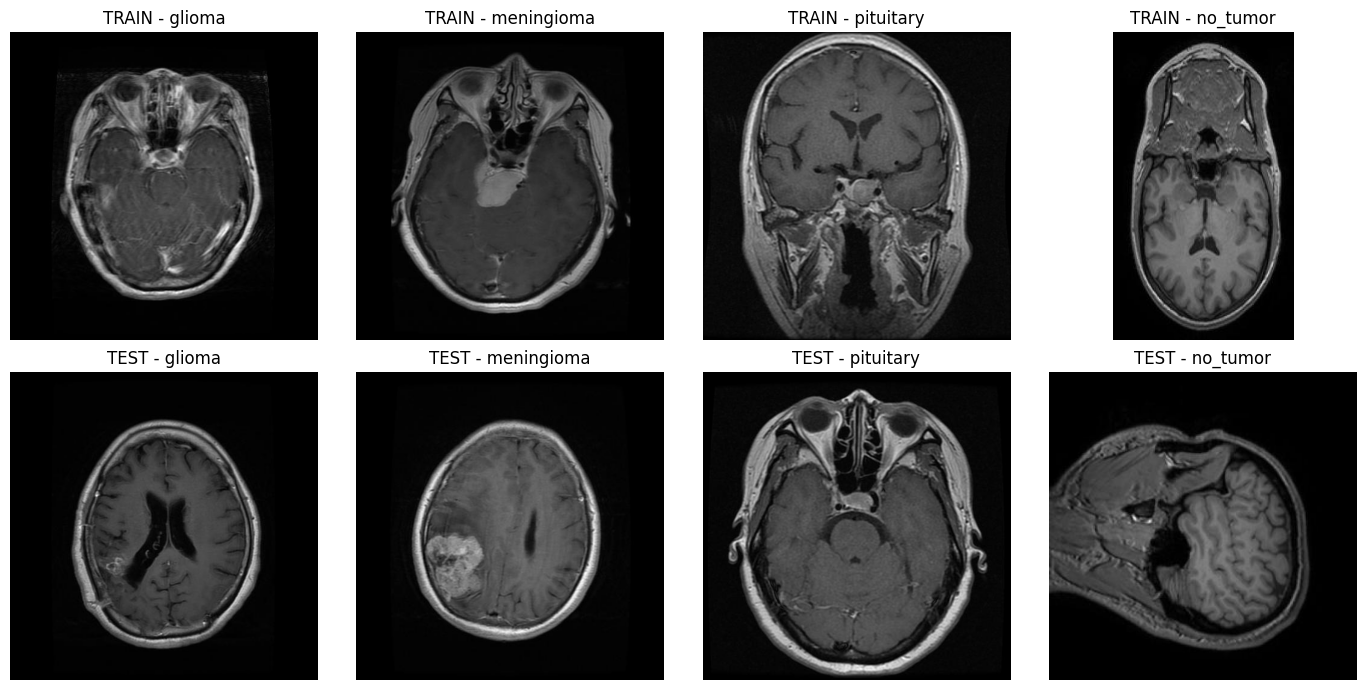

In [2]:

import matplotlib.pyplot as plt
from PIL import Image
import random

random.seed(42)

fig, axes = plt.subplots(2, 4, figsize=(14, 7))

for row, split in enumerate(["train", "test"]):
    for col, class_name in enumerate(classes):
        folder = CLASSIFICATION_DIR / split / class_name

        image_files = [
            p for p in folder.iterdir()
            if p.is_file()
            and p.suffix.lower() in extensions
        ]

        image_path = random.choice(image_files)
        image = Image.open(image_path).convert("RGB")

        axes[row, col].imshow(image)
        axes[row, col].set_title(
            f"{split.upper()} - {class_name}"
        )
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()


In [3]:

from pathlib import Path
from PIL import Image
from collections import Counter
import random

# Dataset paths
DATASET_DIR = Path(
    "/kaggle/input/datasets/briscdataset/brisc2025/brisc2025"
)

CLASSIFICATION_DIR = DATASET_DIR / "classification_task"

classes = [
    "glioma",
    "meningioma",
    "pituitary",
    "no_tumor",
]

extensions = {".jpg", ".jpeg", ".png", ".bmp"}

random.seed(42)

print("Dataset exists:", DATASET_DIR.exists())
print("Classification folder exists:", CLASSIFICATION_DIR.exists())
print("=" * 45)

for class_name in classes:
    folder = CLASSIFICATION_DIR / "train" / class_name

    if not folder.is_dir():
        print(f"\nFolder not found: {folder}")
        continue

    image_files = [
        p for p in folder.iterdir()
        if p.is_file() and p.suffix.lower() in extensions
    ]

    sample_paths = random.sample(
        image_files,
        min(20, len(image_files))
    )

    dimensions = Counter()
    errors = 0

    for path in sample_paths:
        try:
            with Image.open(path) as img:
                img.verify()

            with Image.open(path) as img:
                dimensions[img.size] += 1

        except Exception as e:
            errors += 1
            print(f"Could not read {path.name}: {e}")

    print(f"\nClass: {class_name}")
    print(f"Images sampled: {len(sample_paths)}")
    print(f"Reading errors: {errors}")

    for size, count in dimensions.most_common():
        print(f"  Dimensions {size}: {count} images")


Dataset exists: True
Classification folder exists: True

Class: glioma
Images sampled: 20
Reading errors: 0
  Dimensions (512, 512): 20 images

Class: meningioma
Images sampled: 20
Reading errors: 0
  Dimensions (512, 512): 19 images
  Dimensions (217, 232): 1 images

Class: pituitary
Images sampled: 20
Reading errors: 0
  Dimensions (512, 512): 20 images

Class: no_tumor
Images sampled: 20
Reading errors: 0
  Dimensions (369, 369): 8 images
  Dimensions (216, 369): 6 images
  Dimensions (512, 512): 5 images
  Dimensions (210, 369): 1 images


In [4]:

import tensorflow as tf
from pathlib import Path

SEED = 42
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32

train_dir = CLASSIFICATION_DIR / "train"
test_dir = CLASSIFICATION_DIR / "test"

train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    labels="inferred",
    label_mode="int",
    class_names=classes,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    color_mode="rgb",
    shuffle=True
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    labels="inferred",
    label_mode="int",
    class_names=classes,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    color_mode="rgb",
    shuffle=True
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    labels="inferred",
    label_mode="int",
    class_names=classes,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    color_mode="rgb",
    shuffle=False
)

print("\nClass order:", train_ds.class_names)
print("Image size:", IMAGE_SIZE)
print("Batch size:", BATCH_SIZE)
print("Training batches:", tf.data.experimental.cardinality(train_ds).numpy())
print("Validation batches:", tf.data.experimental.cardinality(val_ds).numpy())
print("Test batches:", tf.data.experimental.cardinality(test_ds).numpy())


Found 5000 files belonging to 4 classes.
Using 4000 files for training.


I0000 00:00:1792791431.309649      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792791431.313560      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Found 5000 files belonging to 4 classes.
Using 1000 files for validation.
Found 1000 files belonging to 4 classes.

Class order: ['glioma', 'meningioma', 'pituitary', 'no_tumor']
Image size: (224, 224)
Batch size: 32
Training batches: 125
Validation batches: 32
Test batches: 32


In [5]:

import tensorflow as tf

print("TensorFlow version:", tf.__version__)

print("\nAvailable GPU devices:")
gpus = tf.config.list_physical_devices("GPU")
print(gpus)

if gpus:
    print("\nGPU is available.")
else:
    print("\nGPU is NOT available. Training would use CPU.")


TensorFlow version: 2.20.0

Available GPU devices:
[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]

GPU is available.


In [6]:
import tensorflow as tf

print(tf.config.list_physical_devices("GPU"))

[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [7]:

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Reproducibility
tf.keras.utils.set_random_seed(42)

# CNN baseline model
model = keras.Sequential([
    layers.Input(shape=(224, 224, 3)),

    # Normalize pixel values from 0-255 to 0-1
    layers.Rescaling(1.0 / 255),

    # First convolution block
    layers.Conv2D(32, 3, activation="relu", padding="same"),
    layers.MaxPooling2D(),

    # Second convolution block
    layers.Conv2D(64, 3, activation="relu", padding="same"),
    layers.MaxPooling2D(),

    # Third convolution block
    layers.Conv2D(128, 3, activation="relu", padding="same"),
    layers.MaxPooling2D(),

    # Classification head
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.4),
    layers.Dense(4, activation="softmax")
])

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,276 (430.77 KB)

 Trainable params: 110,276 (430.77 KB)

 Non-trainable params: 0 (0.00 B)

In [8]:

import tensorflow as tf
from pathlib import Path

# Dataset paths
DATASET_DIR = Path(
    "/kaggle/input/datasets/briscdataset/brisc2025/brisc2025"
)
CLASSIFICATION_DIR = DATASET_DIR / "classification_task"

classes = [
    "glioma",
    "meningioma",
    "pituitary",
    "no_tumor",
]

IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

train_ds = tf.keras.utils.image_dataset_from_directory(
    CLASSIFICATION_DIR / "train",
    labels="inferred",
    label_mode="int",
    class_names=classes,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    CLASSIFICATION_DIR / "train",
    labels="inferred",
    label_mode="int",
    class_names=classes,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    CLASSIFICATION_DIR / "test",
    labels="inferred",
    label_mode="int",
    class_names=classes,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False,
)

print("\nDatasets successfully created.")
print("Training batches:", tf.data.experimental.cardinality(train_ds).numpy())
print("Validation batches:", tf.data.experimental.cardinality(val_ds).numpy())
print("Test batches:", tf.data.experimental.cardinality(test_ds).numpy())


Found 5000 files belonging to 4 classes.
Using 4000 files for training.
Found 5000 files belonging to 4 classes.
Using 1000 files for validation.
Found 1000 files belonging to 4 classes.

Datasets successfully created.
Training batches: 125
Validation batches: 32
Test batches: 32


Epoch 1/15
  3/125 ━━━━━━━━━━━━━━━━━━━━ 7s 62ms/step - accuracy: 0.3663 - loss: 1.3840

I0000 00:00:1792791445.219778      77 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 944ms/step - accuracy: 0.3280 - loss: 1.3532
Epoch 1: val_loss improved from None to 1.16875, saving model to /kaggle/working/best_cnn.keras

Epoch 1: finished saving model to /kaggle/working/best_cnn.keras
125/125 ━━━━━━━━━━━━━━━━━━━━ 157s 1s/step - accuracy: 0.3825 - loss: 1.2929 - val_accuracy: 0.5090 - val_loss: 1.1687
Epoch 2/15
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - accuracy: 0.5486 - loss: 1.0744
Epoch 2: val_loss improved from 1.16875 to 0.86137, saving model to /kaggle/working/best_cnn.keras

Epoch 2: finished saving model to /kaggle/working/best_cnn.keras
125/125 ━━━━━━━━━━━━━━━━━━━━ 7s 57ms/step - accuracy: 0.5792 - loss: 1.0293 - val_accuracy: 0.6630 - val_loss: 0.8614
Epoch 3/15
124/125 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - accuracy: 0.6646 - loss: 0.8625
Epoch 3: val_loss improved from 0.86137 to 0.69675, saving model to /kaggle/working/best_cnn.keras

Epoch 3: finished saving model to /kaggle/working/best_cnn.keras
125/125 ━━━━━━━━━━━━━

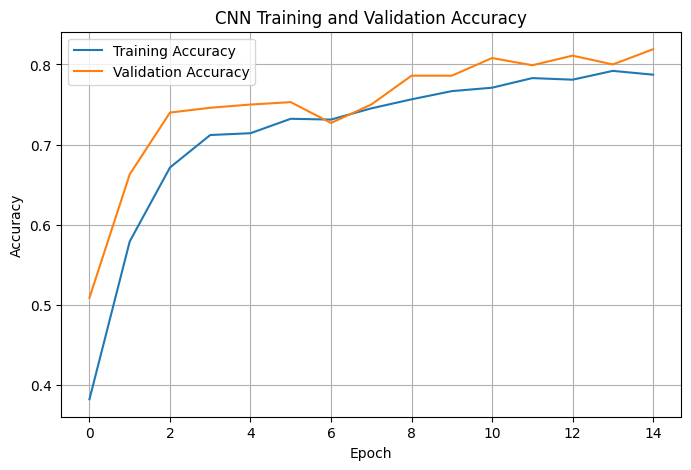

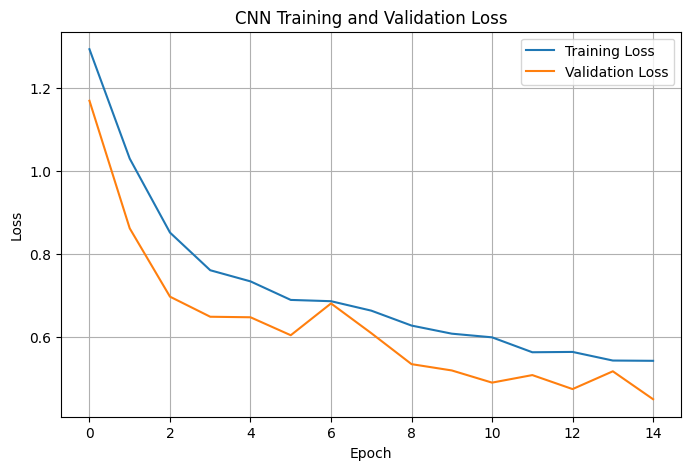

In [9]:

from pathlib import Path
import tensorflow as tf
import matplotlib.pyplot as plt

# Save the best model during training
checkpoint_path = "/kaggle/working/best_cnn.keras"

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=checkpoint_path,
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    )
]

# Train the baseline CNN
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=callbacks
)

print("\nTraining completed.")
print("Best model checkpoint:", checkpoint_path)

# Plot accuracy
plt.figure(figsize=(8, 5))
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("CNN Training and Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()

# Plot loss
plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CNN Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()


32/32 ━━━━━━━━━━━━━━━━━━━━ 27s 841ms/step - accuracy: 0.7670 - loss: 0.5495
32/32 ━━━━━━━━━━━━━━━━━━━━ 2s 44ms/step

Test Loss: 0.5495
Test Accuracy: 0.7670

Classification Report:
              precision    recall  f1-score   support

      glioma     0.8773    0.5630    0.6859       254
  meningioma     0.6768    0.6569    0.6667       306
   pituitary     0.8050    0.9633    0.8771       300
    no_tumor     0.7403    0.9571    0.8349       140

    accuracy                         0.7670      1000
   macro avg     0.7749    0.7851    0.7661      1000
weighted avg     0.7751    0.7670    0.7582      1000



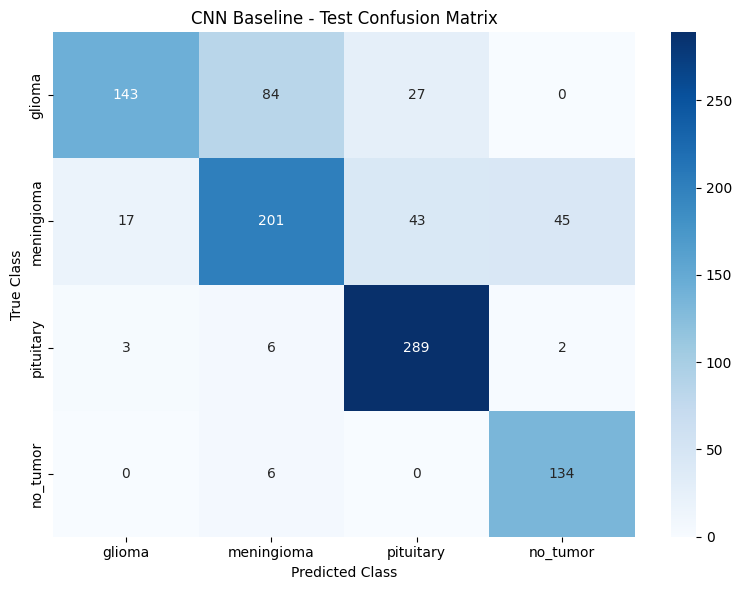

In [10]:

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Evaluate on the held-out test dataset
test_loss, test_accuracy = model.evaluate(
    test_ds,
    verbose=1
)

# Collect true labels
y_true = np.concatenate([
    labels.numpy() for images, labels in test_ds
])

# Predict class probabilities
y_prob = model.predict(test_ds, verbose=1)

# Convert probabilities to predicted class indices
y_pred = np.argmax(y_prob, axis=1)

# Calculate metrics
print(f"\nTest Loss: {test_loss:.4f}")
print(f"Test Accuracy: {accuracy_score(y_true, y_pred):.4f}")

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1, 2, 3],
    target_names=classes,
    digits=4,
    zero_division=0
))

# Confusion Matrix
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1, 2, 3]
)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=classes,
    yticklabels=classes
)

plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.title("CNN Baseline - Test Confusion Matrix")
plt.tight_layout()
plt.show()


In [11]:
import numpy as np
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)

y_true = np.concatenate([
    labels.numpy() for images, labels in test_ds
])

y_prob = model.predict(test_ds, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

print("Accuracy:", accuracy_score(y_true, y_pred))

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1, 2, 3],
    target_names=classes,
    digits=4,
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1, 2, 3]
))

32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step
Accuracy: 0.767

Classification Report:
              precision    recall  f1-score   support

      glioma     0.8773    0.5630    0.6859       254
  meningioma     0.6768    0.6569    0.6667       306
   pituitary     0.8050    0.9633    0.8771       300
    no_tumor     0.7403    0.9571    0.8349       140

    accuracy                         0.7670      1000
   macro avg     0.7749    0.7851    0.7661      1000
weighted avg     0.7751    0.7670    0.7582      1000


Confusion Matrix:
[[143  84  27   0]
 [ 17 201  43  45]
 [  3   6 289   2]
 [  0   6   0 134]]


In [12]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

base_model = keras.applications.EfficientNetB0(
    include_top=False,
    weights="imagenet",
    input_shape=(224, 224, 3)
)

base_model.trainable = False

print("EfficientNetB0 loaded successfully.")
print("Number of layers:", len(base_model.layers))

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
EfficientNetB0 loaded successfully.
Number of layers: 238


In [13]:
from tensorflow import keras
from tensorflow.keras import layers

inputs = keras.Input(shape=(224, 224, 3))

# Extract features using the pretrained model
x = base_model(inputs, training=False)

# Convert feature maps into a feature vector
x = layers.GlobalAveragePooling2D()(x)

# Reduce overfitting
x = layers.Dropout(0.3)(x)

# Classify into four brain image classes
outputs = layers.Dense(4, activation="softmax")(x)

efficientnet_model = keras.Model(
    inputs=inputs,
    outputs=outputs,
    name="EfficientNetB0_Brain_Classification"
)

efficientnet_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

efficientnet_model.summary()

Model: "EfficientNetB0_Brain_Classification"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 4)              │         5,124 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,054,695 (15.47 MB)

 Trainable params: 5,124 (20.02 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [14]:
print("Model exists:", "efficientnet_model" in globals())
print("Training data exists:", "train_ds" in globals())

Model exists: True
Training data exists: True


In [15]:
import tensorflow as tf
from pathlib import Path

CLASSIFICATION_DIR = Path(
    "/kaggle/input/datasets/briscdataset/brisc2025/brisc2025/classification_task"
)

classes = ["glioma", "meningioma", "pituitary", "no_tumor"]

train_ds = tf.keras.utils.image_dataset_from_directory(
    CLASSIFICATION_DIR / "train",
    labels="inferred",
    label_mode="int",
    class_names=classes,
    validation_split=0.2,
    subset="training",
    seed=42,
    image_size=(224, 224),
    batch_size=32,
    color_mode="rgb",
    shuffle=True
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    CLASSIFICATION_DIR / "train",
    labels="inferred",
    label_mode="int",
    class_names=classes,
    validation_split=0.2,
    subset="validation",
    seed=42,
    image_size=(224, 224),
    batch_size=32,
    color_mode="rgb",
    shuffle=True
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    CLASSIFICATION_DIR / "test",
    labels="inferred",
    label_mode="int",
    class_names=classes,
    image_size=(224, 224),
    batch_size=32,
    color_mode="rgb",
    shuffle=False
)

print("All datasets are ready.")

Found 5000 files belonging to 4 classes.
Using 4000 files for training.
Found 5000 files belonging to 4 classes.
Using 1000 files for validation.
Found 1000 files belonging to 4 classes.
All datasets are ready.


In [16]:
import tensorflow as tf
import matplotlib.pyplot as plt

checkpoint_path = "/kaggle/working/best_efficientnetb0.keras"

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=checkpoint_path,
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    )
]

history_efficientnet = efficientnet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=callbacks
)

print("\nEfficientNetB0 training completed.")
print("Best model checkpoint:", checkpoint_path)

Epoch 1/15


2026-10-23 21:42:33.425902: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-23 21:42:33.569569: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-23 21:42:33.939616: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-23 21:42:34.083060: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-23 21:42:34.228356: E external/local_xla/xla/stream_

125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - accuracy: 0.5918 - loss: 0.9983

2026-10-23 21:43:02.474112: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-23 21:43:02.610499: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-23 21:43:02.931469: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-23 21:43:03.075012: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-23 21:43:03.942487: E external/local_xla/xla/stream_


Epoch 1: val_loss improved from None to 0.45363, saving model to /kaggle/working/best_efficientnetb0.keras

Epoch 1: finished saving model to /kaggle/working/best_efficientnetb0.keras
125/125 ━━━━━━━━━━━━━━━━━━━━ 56s 205ms/step - accuracy: 0.7013 - loss: 0.7780 - val_accuracy: 0.8650 - val_loss: 0.4536
Epoch 2/15
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - accuracy: 0.8414 - loss: 0.4734
Epoch 2: val_loss improved from 0.45363 to 0.35582, saving model to /kaggle/working/best_efficientnetb0.keras

Epoch 2: finished saving model to /kaggle/working/best_efficientnetb0.keras
125/125 ━━━━━━━━━━━━━━━━━━━━ 7s 53ms/step - accuracy: 0.8397 - loss: 0.4645 - val_accuracy: 0.8890 - val_loss: 0.3558
Epoch 3/15
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - accuracy: 0.8598 - loss: 0.4005
Epoch 3: val_loss improved from 0.35582 to 0.31570, saving model to /kaggle/working/best_efficientnetb0.keras

Epoch 3: finished saving model to /kaggle/working/best_efficientnetb0.keras
125/125 ━━━━━━━━━━━━━━━━━━━━ 

In [17]:
import os

print("Working directory files:")
print(os.listdir("/kaggle/working"))

print("\nSearching for saved EfficientNet models...")

for root, dirs, files in os.walk("/kaggle/working"):
    for file in files:
        if "efficientnet" in file.lower() or file.endswith(".keras"):
            print(os.path.join(root, file))

Working directory files:
['__notebook__.ipynb', 'best_cnn.keras', 'best_efficientnetb0.keras']

Searching for saved EfficientNet models...
/kaggle/working/best_cnn.keras
/kaggle/working/best_efficientnetb0.keras


In [18]:
print("efficientnet_model exists:",
      "efficientnet_model" in globals())

print("history_efficientnet exists:",
      "history_efficientnet" in globals())

print("test_ds exists:",
      "test_ds" in globals())

efficientnet_model exists: True
history_efficientnet exists: True
test_ds exists: True


In [19]:
import tensorflow as tf
from pathlib import Path

DATASET_DIR = Path(
    "/kaggle/input/datasets/briscdataset/brisc2025/brisc2025"
)
CLASSIFICATION_DIR = DATASET_DIR / "classification_task"

classes = ["glioma", "meningioma", "pituitary", "no_tumor"]
SEED = 42
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32

train_dir = CLASSIFICATION_DIR / "train"
test_dir = CLASSIFICATION_DIR / "test"

train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    labels="inferred",
    label_mode="int",
    class_names=classes,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    color_mode="rgb",
    shuffle=True
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    labels="inferred",
    label_mode="int",
    class_names=classes,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    color_mode="rgb",
    shuffle=True
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    labels="inferred",
    class_names=classes,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    color_mode="rgb",
    shuffle=False
)

print("\nAll datasets recreated successfully.")

Found 5000 files belonging to 4 classes.
Using 4000 files for training.
Found 5000 files belonging to 4 classes.
Using 1000 files for validation.
Found 1000 files belonging to 4 classes.

All datasets recreated successfully.


In [20]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Load EfficientNetB0 pretrained on ImageNet
base_model = keras.applications.EfficientNetB0(
    include_top=False,
    weights="imagenet",
    input_shape=(224, 224, 3)
)

# Freeze the pretrained feature extractor
base_model.trainable = False

# Build the classification model
inputs = keras.Input(shape=(224, 224, 3))

# EfficientNetB0 includes its own input preprocessing
x = base_model(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)

outputs = layers.Dense(
    4,
    activation="softmax"
)(x)

efficientnet_model = keras.Model(
    inputs=inputs,
    outputs=outputs,
    name="EfficientNetB0_Brain_Classification"
)

# Compile
efficientnet_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

efficientnet_model.summary()

Model: "EfficientNetB0_Brain_Classification"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4)              │         5,124 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,054,695 (15.47 MB)

 Trainable params: 5,124 (20.02 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [21]:
import os
import tensorflow as tf
from tensorflow import keras

checkpoint_path = "/kaggle/working/best_efficientnetb0.keras"

callbacks = [
    keras.callbacks.ModelCheckpoint(
        filepath=checkpoint_path,
        monitor="val_loss",
        save_best_only=True,
        save_weights_only=False,
        mode="min",
        verbose=1
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        mode="min",
        verbose=1
    )
]

history_efficientnet = efficientnet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=callbacks,
    verbose=1
)

print("\nTraining completed.")
print("Best model file exists:", os.path.exists(checkpoint_path))
print("Saved model size (MB):",
      round(os.path.getsize(checkpoint_path) / (1024 ** 2), 2)
      if os.path.exists(checkpoint_path) else "Not found")

Epoch 1/15
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - accuracy: 0.5789 - loss: 1.0186
Epoch 1: val_loss improved from None to 0.44840, saving model to /kaggle/working/best_efficientnetb0.keras

Epoch 1: finished saving model to /kaggle/working/best_efficientnetb0.keras
125/125 ━━━━━━━━━━━━━━━━━━━━ 41s 148ms/step - accuracy: 0.7090 - loss: 0.7751 - val_accuracy: 0.8620 - val_loss: 0.4484
Epoch 2/15
124/125 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - accuracy: 0.8517 - loss: 0.4693
Epoch 2: val_loss improved from 0.44840 to 0.35211, saving model to /kaggle/working/best_efficientnetb0.keras

Epoch 2: finished saving model to /kaggle/working/best_efficientnetb0.keras
125/125 ━━━━━━━━━━━━━━━━━━━━ 7s 53ms/step - accuracy: 0.8470 - loss: 0.4565 - val_accuracy: 0.8840 - val_loss: 0.3521
Epoch 3/15
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 0.8574 - loss: 0.4031
Epoch 3: val_loss improved from 0.35211 to 0.31640, saving model to /kaggle/working/best_efficientnetb0.keras

Epoch 3: finished s

Saved model loaded successfully.
32/32 ━━━━━━━━━━━━━━━━━━━━ 16s 196ms/step - accuracy: 0.8980 - loss: 0.2589
32/32 ━━━━━━━━━━━━━━━━━━━━ 16s 271ms/step

Test Loss: 0.2589
Test Accuracy: 0.8980

Classification Report:
              precision    recall  f1-score   support

      glioma     0.8694    0.8386    0.8537       254
  meningioma     0.8537    0.8203    0.8367       306
   pituitary     0.9545    0.9800    0.9671       300
    no_tumor     0.9150    1.0000    0.9556       140

    accuracy                         0.8980      1000
   macro avg     0.8982    0.9097    0.9033      1000
weighted avg     0.8965    0.8980    0.8968      1000



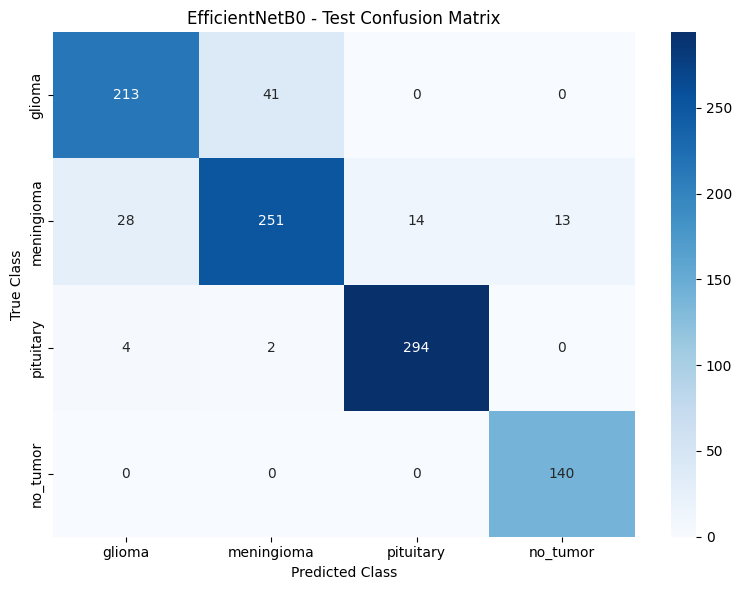

In [22]:
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Load the best saved model
checkpoint_path = "/kaggle/working/best_efficientnetb0.keras"

efficientnet_model = tf.keras.models.load_model(
    checkpoint_path
)

print("Saved model loaded successfully.")

# Evaluate on the test set
test_loss, test_accuracy = efficientnet_model.evaluate(
    test_ds,
    verbose=1
)

# Collect true labels
y_true = np.concatenate([
    labels.numpy()
    for images, labels in test_ds
])

# Generate predictions
y_prob = efficientnet_model.predict(test_ds, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

print(f"\nTest Loss: {test_loss:.4f}")
print(f"Test Accuracy: {accuracy_score(y_true, y_pred):.4f}")

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1, 2, 3],
    target_names=classes,
    digits=4,
    zero_division=0
))

# Confusion matrix
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1, 2, 3]
)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=classes,
    yticklabels=classes
)

plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.title("EfficientNetB0 - Test Confusion Matrix")
plt.tight_layout()
plt.show()